# 01 - Exploración Técnica del Dataset

**Proyecto:** Análisis de riesgo crediticio · South German Credit (UCI)  
**Unidad II:** Diagnóstico del conjunto de datos del Proyecto Integrador  
**Herramientas:** Python 3.x · Pandas · Matplotlib · Git

Este notebook sigue el procedimiento solicitado: carga y exploración inicial, diagnóstico de calidad,
análisis estadístico, detección de atípicos y visualización inicial. La interpretación escrita de cada
apartado está incluida en las celdas markdown posteriores y se amplía en
`docs/analisis/exploracion_tecnica.md`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110


## 2) Carga y exploración inicial

El archivo crudo `SouthGermanCredit.asc` está delimitado por espacios y usa nombres de columnas en alemán.


In [2]:
df = pd.read_csv('../data/raw/SouthGermanCredit.asc', sep=' ')
df.head()


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,wohnzeit,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,4,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,2,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,4,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,2,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,4,2,38,1,2,2,2,2,1,1,1


**Interpretación de `df.head()`**

Las primeras cinco filas confirman el hallazgo clave del primer contacto: **los datos vienen totalmente
codificados en enteros**, sin texto ni unidades. El dataset no se puede leer por sí solo; necesita
`codetable.txt` para traducir los códigos a significados (por ejemplo `laufkont = status`, cuenta corriente
del deudor). Además, las primeras filas corresponden casi todas a `kredit = 1` (crédito bueno): la muestra
está **ordenada por la clase objetivo**, no por fecha, por lo que nunca debe interpretarse el orden del
archivo como una serie temporal.


In [3]:
df.shape


(1000, 21)

In [4]:
df.columns


Index(['laufkont', 'laufzeit', 'moral', 'verw', 'hoehe', 'sparkont', 'beszeit', 'rate', 'famges', 'buerge', 'wohnzeit', 'verm', 'alter', 'weitkred', 'wohn', 'bishkred', 'beruf', 'pers', 'telef',
       'gastarb', 'kredit'],
      dtype='str')

**Interpretación de `df.shape` y `df.columns`**

`(1000, 21)`: 1000 créditos y 21 variables, exactamente lo publicado por UCI, de modo que no se perdió
ninguna fila en la lectura. De las 21 columnas, 20 son candidatas a predictoras y `kredit` es la variable
objetivo. Los nombres (en alemán: `laufkont`, `moral`, `verw`, `hoehe`…) no son autoexplicativos; esto
obliga a mantener el diccionario de datos visible durante todo el análisis.


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   laufkont  1000 non-null   int64
 1   laufzeit  1000 non-null   int64
 2   moral     1000 non-null   int64
 3   verw      1000 non-null   int64
 4   hoehe     1000 non-null   int64
 5   sparkont  1000 non-null   int64
 6   beszeit   1000 non-null   int64
 7   rate      1000 non-null   int64
 8   famges    1000 non-null   int64
 9   buerge    1000 non-null   int64
 10  wohnzeit  1000 non-null   int64
 11  verm      1000 non-null   int64
 12  alter     1000 non-null   int64
 13  weitkred  1000 non-null   int64
 14  wohn      1000 non-null   int64
 15  bishkred  1000 non-null   int64
 16  beruf     1000 non-null   int64
 17  pers      1000 non-null   int64
 18  telef     1000 non-null   int64
 19  gastarb   1000 non-null   int64
 20  kredit    1000 non-null   int64
dtypes: int64(21)
memory usage: 164.2 KB


In [6]:
df.dtypes


laufkont    int64
laufzeit    int64
moral       int64
verw        int64
hoehe       int64
sparkont    int64
beszeit     int64
rate        int64
famges      int64
buerge      int64
wohnzeit    int64
verm        int64
alter       int64
weitkred    int64
wohn        int64
bishkred    int64
beruf       int64
pers        int64
telef       int64
gastarb     int64
kredit      int64
dtype: object

**Interpretación de `df.info()` y `df.dtypes`**

Todas las columnas se cargaron como `int64` (memoria ligera, ~164 KB) y `RangeIndex: 0 to 999` confirma un
índice continuo sin filas omitidas. No existe ninguna columna de tipo `object` ni `datetime`: variables que
conceptualmente son **categóricas** (`laufkont`, `moral`, `verw`,…) llegan como números. Es una
representación válida para modelar, pero peligrosa para interpretar: un algoritmo podría suponer que
`verw = 10` (negocio) es “doble” que `verw = 5` (electrodomésticos), comparación sin sentido. En la etapa de
preparación hay que tratarlas como categóricas, distinguiendo odominales de nominales.


In [7]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
laufkont,1000.0,2.577,1.257638,1.0,1.0,2.0,4.00,4.0
laufzeit,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
moral,1000.0,2.545,1.083120,0.0,2.0,2.0,4.00,4.0
verw,1000.0,2.828,2.744439,0.0,1.0,2.0,3.00,10.0
hoehe,1000.0,3271.248,2822.751760,250.0,1365.5,2319.5,3972.25,18424.0
sparkont,1000.0,2.105,1.580023,1.0,1.0,1.0,3.00,5.0
beszeit,1000.0,3.384,1.208306,1.0,3.0,3.0,5.00,5.0
rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
famges,1000.0,2.682,0.708080,1.0,2.0,3.0,3.00,4.0
buerge,1000.0,1.145,0.477706,1.0,1.0,1.0,1.00,3.0


**Interpretación de `df.describe()`**

- Variables cuantitativas reales: `laufzeit` (4 a 72 meses), `hoehe` (250 a 18 424) y `alter` (19 a 75).
- Las variables codificadas se camuflan entre ellas: sus estadísticos numéricos carecen de interpretación
monetaria o temporal; solo delimitan el rango de códigos utilizados.
- `kredit` tiene media 0.700: el **70 % de la muestra es clase 1 (`good`)**. El desbalance 700/300 existe
por diseño: los créditos malos fueron sobrerrepresentados al construir la muestra, por lo que su proporción
no equivale a la tasa real de incumplimiento de 1973–1975.
- El 50 % central de los montos está entre ~1 366 y ~3 972 DM, con media (3 271) mayor que la mediana
(2 320): señal de **distribución sesgada a la derecha**.


## 5) Diagnóstico de calidad

### 5.1 Valores faltantes


In [8]:
df.isnull().sum()


laufkont    0
laufzeit    0
moral       0
verw        0
hoehe       0
sparkont    0
beszeit     0
rate        0
famges      0
buerge      0
wohnzeit    0
verm        0
alter       0
weitkred    0
wohn        0
bishkred    0
beruf       0
pers        0
telef       0
gastarb     0
kredit      0
dtype: int64

**Interpretación de `df.isnull().sum()`**

Todas las variables reportan **0 valores faltantes** (1000 no nulos en las 21 columnas de `df.info()`), en
coincidencia con la documentación oficial de UCI (“Has Missing Values? No”). Tratamiento propuesto para
etapas posteriores: **no imputar**. En un dataset codificado, un “faltante” no aparecería como `NaN` sino
como código inválido tras la decodificación, por lo que la defensa correcta es validar rangos (paso 5.3).
Como regla defensiva del ETL: si aparece un código fuera de catálogo, se recodifica como categoría
“desconocido” en las categóricas y nunca se descartan filas en un dataset de solo 1000 registros.


### 5.2 Registros duplicados


In [9]:
df.duplicated().sum()


np.int64(0)

**Interpretación de `df.duplicated().sum()`**

Existen **0 registros duplicados exactos**. La causa típica de duplicados que aquí no se presenta es la
captura manual o los *joins* de un ETL; en este proyecto el riesgo más probable es duplicar filas si el
mismo archivo se carga dos veces en el Data Warehouse. Tratamiento propuesto: no hacer nada en los datos
crudos; agregar una **llave primaria sintética** (`sk_credito`) en el DW y revisar `duplicated().sum()`
después de cada transformación para detectar duplicados inducidos por el código. Dos créditos con perfil
idéntico (misma combinación de los 21 campos) pueden existir legítimamente: un “duplicado” aquí no es
evidencia de doble captura, y por eso la comprobación se repetirá en el ETL y no en el origen.


### 5.3 Valores incorrectos o inconsistentes

Se valida que cada columna codificada contenga únicamente los códigos del `codetable.txt` y que las
cuantitativas no presenten valores absurdos.


In [10]:
codigos_validos = {
    'laufkont': range(1, 5), 'moral': range(0, 5), 'verw': range(0, 11),
    'sparkont': range(1, 6), 'beszeit': range(1, 6), 'rate': range(1, 5),
    'famges': range(1, 5), 'buerge': range(1, 4), 'wohnzeit': range(1, 5),
    'verm': range(1, 5), 'weitkred': range(1, 4), 'wohn': range(1, 4),
    'bishkred': range(1, 5), 'beruf': range(1, 5), 'pers': range(1, 3),
    'telef': range(1, 3), 'gastarb': range(1, 3), 'kredit': range(0, 2),
}
for col, codigos in codigos_validos.items():
    fuera = df.loc[~df[col].isin(codigos), col]
    if len(fuera):
        print('FUERA DE CODIGO:', col, sorted(fuera.unique()))
for col, codigos in codigos_validos.items():
    sin_datos = sorted(set(codigos) - set(df[col].unique()))
    if sin_datos:
        print('CODIGO QUE NO APARECE EN LOS DATOS:', col, sin_datos)

# Rangos lógicos de las cuantitativas
print('creditos con duracion <= 0:', int((df['laufzeit'] <= 0).sum()))
print('creditos con monto <= 0:', int((df['hoehe'] <= 0).sum()))
print('clientes menores de 18 anios:', int((df['alter'] < 18).sum()))


CODIGO QUE NO APARECE EN LOS DATOS: verw [7]
creditos con duracion <= 0: 0
creditos con monto <= 0: 0
clientes menores de 18 anios: 0


**Interpretación de 5.3**

1. **Cero códigos fuera del catálogo**: la codificación es formalmente correcta; es un dataset curado y no
se detectaron errores de captura.
2. **Hallazgo real de inconsistencia**: el código `verw = 7` (propósito *educación*) existe en el catálogo
pero no aparece en ningún registro. No es un error: es una **categoría vacía**; al hacer One-Hot-Encoding
producirá una columna llena de ceros y conviene descartarla.
3. **Colisiones de codificación**: `moral` empieza en 0 mientras el resto empieza en 1; `gastarb` usa
“1 = sí, 2 = no” pero `telef` usa “1 = no, 2 = sí” — **direcciones opuestas** que deben homogeneizarse a 0/1
antes de cualquier modelo lineal, porque si no el signo de un coeficiente resulta ininterpretable.
4. **`pers` es ordinal invertido**: el código 1 significa “3 o más personas a cargo” y el 2 significa “0 a 2
personas”. Tratarlo como escala ascendente invertiría por completo su significado.
5. **Rangos lógicos válidos**: no hay duraciones ni montos ≤ 0 ni clientes menores de 18 años; los extremos
(72 meses, 18 424 DM, 75 años) son valores altos pero plausibles, no errores.


## 6) Análisis estadístico inicial

Variables elegidas por su centralidad en el problema: `laufzeit`, `hoehe` y `alter` (núcleo del perfil
financiero del cliente).


In [11]:
cols = ['laufzeit', 'hoehe', 'alter']
stats = pd.DataFrame({
    'media': df[cols].mean(), 'mediana': df[cols].median(), 'minimo': df[cols].min(),
    'maximo': df[cols].max(), 'desv_est': df[cols].std(),
    'Q1': df[cols].quantile(.25), 'Q3': df[cols].quantile(.75),
})
stats.round(2)


,media,mediana,minimo,maximo,desv_est,Q1,Q3
laufzeit,20.90,18.0,4,72,12.06,12.0,24.00
hoehe,3271.25,2319.5,250,18424,2822.75,1365.5,3972.25
alter,35.54,33.0,19,75,11.35,27.0,42.00


**Interpretación de las estadísticas**

- `laufzeit`: media 20.90 frente a mediana 18. La mayoría de los créditos son de 6–24 meses, con una cola
de plazos largos (máximo 72). Es relevante para el riesgo: la clase `bad` tiene una duración media de
24.86 meses frente a 19.21 de `good`: **plazos más largos se asocian a más riesgo**.
- `hoehe`: media 3 271 DM y mediana 2 320 DM, con desviación estándar de 2 823 (casi del tamaño de la
mediana): dispersión altísima y sesgo a la derecha. Los créditos `bad` promedian 3 938 DM frente a
2 985 DM de los `good`: **montos mayores se asocian a riesgo**, y buena parte de los outliers proviene de
esta cola.
- `alter`: media 35.5 años, mediana 33, rango 19–75: población adulta-joven; los `bad` promedian 34.0 años
frente a 36.2, un patrón débil.
En conjunto, la enorme desviación estándar de `hoehe` explica por qué la regresión sobre el monto (sección
9) exigirá escalamiento o transformación logarítmica para no dominar la función de pérdida.


## 7) Detección inicial de valores atípicos

Regla de Tukey con IQR = Q3 − Q1: es atípico si el valor < Q1 − 1.5·IQR o > Q3 + 1.5·IQR.
**No se eliminará ningún registro en esta etapa.**


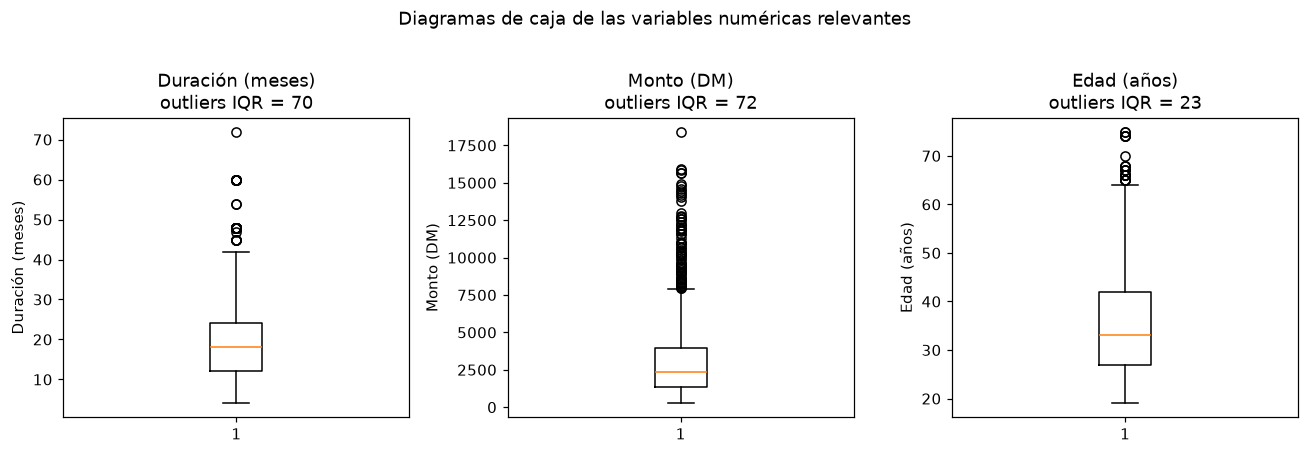

laufzeit: limites [-6.0, 42.0] outliers = 70 (7.0%)
hoehe: limites [-2544.6, 7882.4] outliers = 72 (7.2%)
alter: limites [4.5, 64.5] outliers = 23 (2.3%)


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col, titulo in zip(axes, ['laufzeit', 'hoehe', 'alter'],
                           ['Duración (meses)', 'Monto (DM)', 'Edad (años)']):
    s = df[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = int(((s < lim_inf) | (s > lim_sup)).sum())
    ax.boxplot(s)
    ax.set_title(f'{titulo}\noutliers IQR = {n_out}')
    ax.set_ylabel(titulo)
fig.suptitle('Diagramas de caja de las variables numéricas relevantes', y=1.02)
fig.tight_layout()
plt.show()

for col in ['laufzeit', 'hoehe', 'alter']:
    s = df[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (s < lim_inf) | (s > lim_sup)
    print(f'{col}: limites [{lim_inf:.1f}, {lim_sup:.1f}] outliers = {mask.sum()} ({mask.mean()*100:.1f}%)')


**Interpretación de los boxplots**

- **`laufzeit` — 70 outliers (7.0 %, límite superior 42 meses).** La caja llega casi exactamente al límite
porque los plazos se fijan en múltiplos comerciales (24, 30, 36…). Fuera del límite aparecen 45, 47, 48, 54,
60 y 72 meses: **no son errores**, son plazos reales de la época. Tratamiento propuesto: agrupar en
“corto/medio/largo plazo” en vez de recortar, conservando la señal predictiva.
- **`hoehe` — 72 outliers (7.2 %, límite superior 7 882 DM).** La cola llega hasta 18 424 DM y son créditos
grandes reales (varios resultan ser `bad`). Tratamiento propuesto: estandarización (para modelos lineales)
o transformación logarítmica; nunca eliminación de filas.
- **`alter` — 23 outliers (2.3 %, límite superior 64.5).** Clientes de 65 a 75 años, mayores reales, no
errores. Tratamiento propuesto: conservar y tratar la edad como continua (o crear el grupo “65+” en el Data
Mart).

Conclusión: los tres grupos de atípicos corresponden a **perfiles reales y legítimos**, no a errores de
captura. El dataset no requiere limpieza agresiva sino transformación adecuada según el modelo.


## 8) Visualización inicial

Cuatro figuras con título y ejes identificados. También se guardan en `docs/analisis/figuras/` como
`fig1`…`fig5` para el informe MD/HTML.


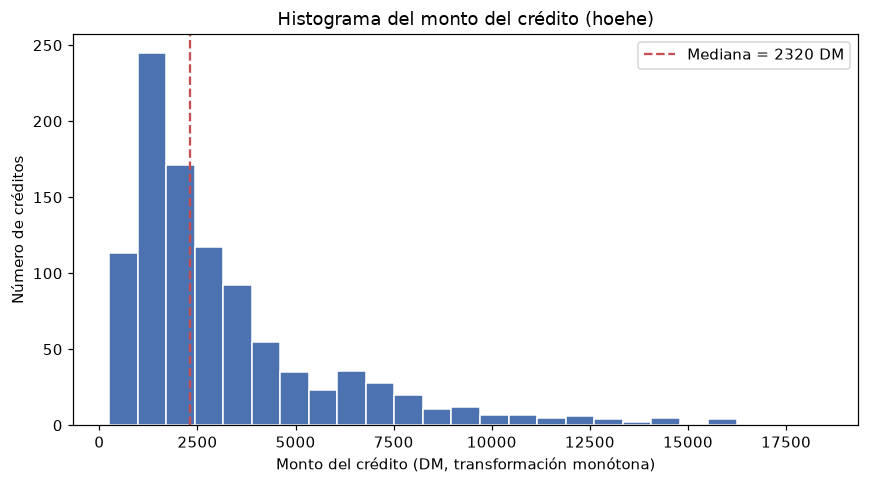

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df['hoehe'], bins=25, color='#4C72B0', edgecolor='white')
ax.axvline(df['hoehe'].median(), color='#C44E52', linestyle='--',
           label=f"Mediana = {df['hoehe'].median():.0f} DM")
ax.set_title('Histograma del monto del crédito (hoehe)')
ax.set_xlabel('Monto del crédito (DM, transformación monótona)')
ax.set_ylabel('Número de créditos')
ax.legend()
fig.tight_layout()
plt.show()


**Histograma del monto.** El grueso de los créditos está entre 250 y 6 000 DM, con una larga cola a la
derecha hasta 18 424 DM. La mediana (2 320 DM) queda a la izquierda de la media (3 271 DM): sesgo positivo
clásico ya visto en `describe()`. Implicación práctica: sin transformación log o escalado, los modelos
lineales quedarían dominados por pocos créditos grandes y el MAE/RMSE se expresaría en monto demasiado
variable.


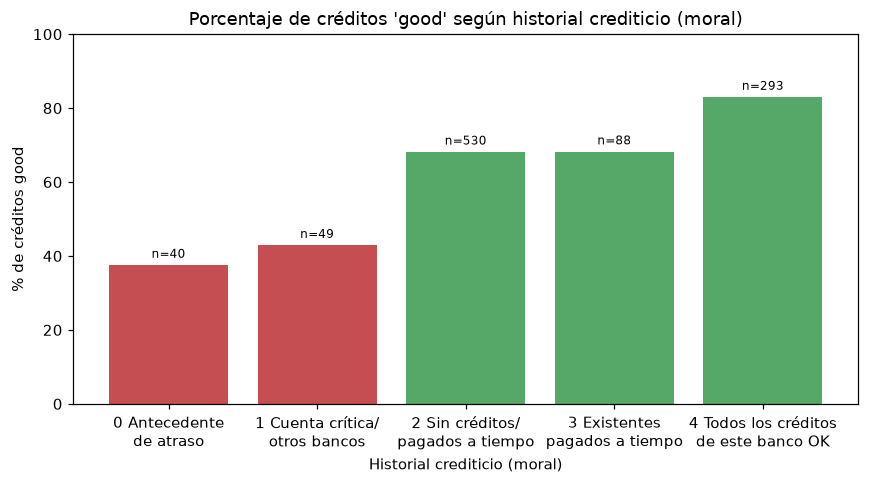

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
tasa = df.groupby('moral')['kredit'].mean() * 100
conteo = df['moral'].value_counts().sort_index()
etiquetas = {
    0: '0 Antecedente\nde atraso',
    1: '1 Cuenta crítica/\notros bancos',
    2: '2 Sin créditos/\npagados a tiempo',
    3: '3 Existentes\npagados a tiempo',
    4: '4 Todos los créditos\nde este banco OK',
}
barras = ax.bar([etiquetas[i] for i in tasa.index], tasa.values,
                color=['#C44E52' if v < 50 else '#55A868' for v in tasa.values])
for barra, n in zip(barras, conteo.values):
    ax.text(barra.get_x() + barra.get_width()/2, barra.get_height() + 2,
            f'n={n}', ha='center', fontsize=8)
ax.set_title("Porcentaje de créditos 'good' según historial crediticio (moral)")
ax.set_xlabel('Historial crediticio (moral)')
ax.set_ylabel('% de créditos good')
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()


**Barras por historial crediticio.** Los créditos con historial problemático (moral = 0 y 1) muestran la
**menor** tasa de pago (< 50 % de `good`, en rojo), mientras que “todos los créditos de este banco OK”
(moral = 4, n = 293) supera el 85 %. Esta será una de las variables con mayor poder de separación en la
tarea de clasificación de la Unidad III, y el contraste rojo/verde es el tipo de regla que el dashboard
podrá comunicar.


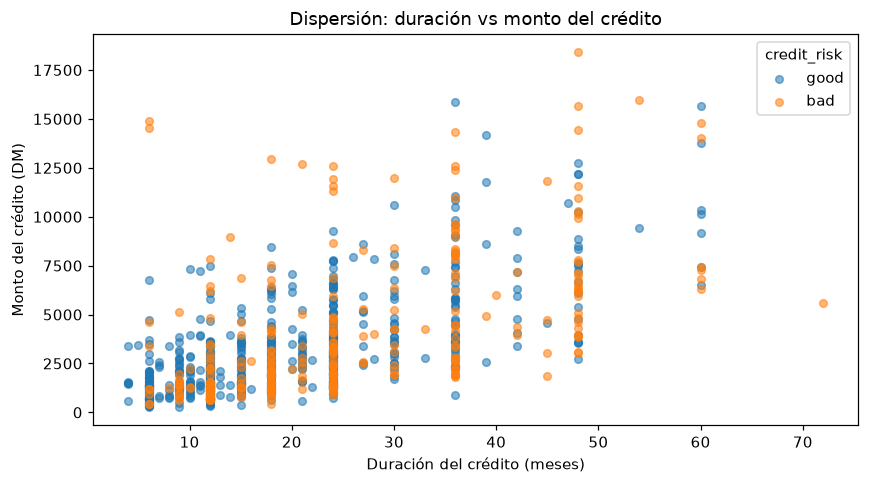

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
good, bad = df[df['kredit'] == 1], df[df['kredit'] == 0]
ax.scatter(good['laufzeit'], good['hoehe'], alpha=0.55, label='good', s=25)
ax.scatter(bad['laufzeit'], bad['hoehe'], alpha=0.55, label='bad', s=25)
ax.set_title('Dispersión: duración vs monto del crédito')
ax.set_xlabel('Duración del crédito (meses)')
ax.set_ylabel('Monto del crédito (DM)')
ax.legend(title='credit_risk')
fig.tight_layout()
plt.show()


**Dispersión monto–plazo.** La correlación `laufzeit–hoehe` es 0.625 (positiva y fuerte), visible en la
nube diagonal: a mayor plazo, mayor monto. Los `bad` se concentran en la zona de plazos largos y montos
grandes. Esta figura es literalmente el fundamento de la propuesta de regresión de la sección 9.


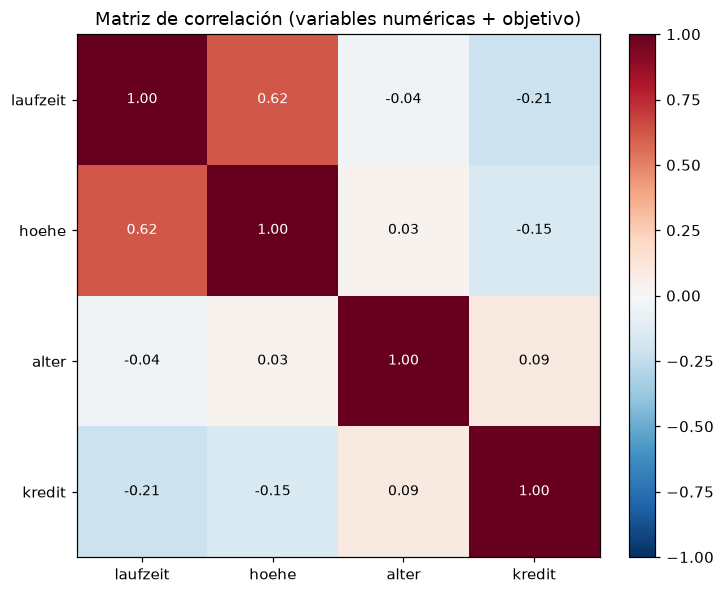

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
corr = df[['laufzeit', 'hoehe', 'alter', 'kredit']].corr()
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i, j]) > 0.5 else 'black', fontsize=9)
ax.set_title('Matriz de correlación (variables numéricas + objetivo)')
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()


**Matriz de correlación.** Entre predictoras no hay colinealidad fuerte (máximo 0.63 entre monto y plazo):
buena noticia para una regresión lineal. `kredit` se correlaciona negativamente con duración (−0.215) y con
monto (−0.155): plazos más cortos y montos menores se asocian a créditos buenos. Con `alter` la relación es
casi nula (0.091): la edad, por sí sola, no discriminara el riesgo y probablemente entre con peso pequeño.
_Nota:_ `hoehe` es una transformación monótona del monto original (UCI no documenta exactamente cuál), por
lo que las correlaciones son válidas pero los valores absolutos de `hoehe` no se interpretan como pesosexactos en DM (solo dirección y orden).


## 9) Preparación para análisis posteriores (propuestas)

**Regresión — objetivo: `hoehe`.** Predecir el monto del crédito con `laufzeit` (correlación 0.625, la
relación más fuerte del dataset), `laufkont` (estado de cuenta como proxy de capacidad de pago), `verw`
(propósito), `sparkont`, `beszeit`, `moral` y `alter` como entradas. La pregunta de Unidad I no es solo
“¿pagará?” sino “¿cuánto se expone el banco?”: un crédito grande fallido cuesta mucho más que uno pequeño.

**Clasificación — objetivo: `kredit`, clases 0 = bad / 1 = good.** Candidatas: `moral` (la más
discriminante según la figura de barras), `laufkont`, `laufzeit`, `sparkont`, `beszeit`, `verm` y
`bishkred`. Restricción documentada: desbalance 700/300 por diseño de la muestra; por eso la métrica
principal de evaluación no será accuracy, sino recall/F1 de la clase `bad` y ROC–AUC.

**Agrupamiento (clustering).** Sobre perfiles de cliente: `hoehe`, `laufzeit` y `alter` estandarizadas,
combinadas con `sparkont`, `verm`, `wohn`, `beszeit` y `laufkont` codificadas, para buscar 3–5 perfiles de
cliente. Evaluación con Silhouette + validación de negocio (tasa de `bad` y monto medio por cluster), que
alimentará el Data Mart del dashboard.


## 10) Conclusión del diagnóstico

1. **¿Qué información contiene el dataset?** 1000 solicitudes de crédito de un banco alemán (1973–1975)
descritas con 21 variables: cuenta corriente, historial, propósito, montos/plazos, ahorros, empleo,
residencia, bienes y el resultado del contrato (`kredit`).
2. **Nivel de calidad.** Alto: 0 faltantes, 0 duplicados, 0 códigos fuera de catálogo, 0 errores lógicos.
3. **Problemas identificados.** Desbalance 70/30 por diseño; colisiones de codificación (`moral` desde 0,
`pers` ordinal invertido, `telef`/`gastarb` con direcciones opuestas); categoría vacía `verw = 7`; `hoehe`
con transformación monótona no documentada; `famges` que mezcla sexo y estado civil.
4. **Variables que requieren tratamiento.** Las 18 codificadas deben decodificarse; las binarias
homogeneizarse a 0/1; `hoehe` requiere escalamiento/log; `famges` debe documentarse como limitación.
5. **¿Existen valores faltantes?** No (0 de 1000 en todas las columnas).
6. **¿Existen registros duplicados?** No (0).
7. **¿Existen valores atípicos?** Sí: 70 en duración (7.0 %), 72 en monto (7.2 %), 23 en edad (2.3 %).
Todos corresponden a perfiles reales; no se eliminan.
8. **¿Qué transformaciones serán necesarias?** Decodificación con `codetable.txt`, normalización 0/1,
One-Hot para nominales, escalado para modelos lineales, creación de `sk_credito` y carga al DW/Data Mart.
9. **¿Los datos son adecuados para continuar?** Sí: calidad alta, tamaño manejable (1000 × 21) y señales
útiles ya visibles (monto, plazo, historial) para los objetivos de Unidad I.
10. **¿Qué conocimiento podría obtenerse?** Tasas de riesgo por perfil/segmento, importancia relativa de
cada variable, estimación del monto solicitado, reglas del tipo “historial X + plazo Y → riesgo Z” y
segmentos de cliente para el dashboard.
